In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames[:20]:
        print(os.path.join(dirname, filename))

In [ ]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/feature_time_48k_2048_load_1.csv')
print(df.shape)
print(df.columns.tolist())
print(df.head())
# find the label column — likely 'fault' or 'label' or last column
print(df.iloc[:, -1].value_counts())

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

X = df.drop(columns=['fault'])
le = LabelEncoder()
y = le.fit_transform(df['fault'])          # XGBoost needs numeric labels

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

clf = XGBClassifier(random_state=42, eval_metric='mlogloss')
clf.fit(Xtr_s, ytr)

pred = clf.predict(Xte_s)
print(classification_report(yte, pred, target_names=le.classes_))

In [ ]:
import shap
import matplotlib.pyplot as plt

# SHAP explainer for the tree model
explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(Xte_s)

# Global feature importance across all classes
shap.summary_plot(shap_values, Xte_s, feature_names=X.columns.tolist(),
                  plot_type="bar", show=True)

In [ ]:
# Detailed: how each feature pushes predictions (beeswarm), for one class
# shap_values is a list (one array per class); pick a class index
class_idx = list(le.classes_).index('Ball_021_1')   # the hard class
shap.summary_plot(shap_values[class_idx], Xte_s,
                  feature_names=X.columns.tolist(), show=True)

In [ ]:
import numpy as np
print(type(shap_values), np.array(shap_values).shape)  # confirm the shape first

In [ ]:
class_idx = list(le.classes_).index('Ball_021_1')
# new SHAP: shape is (samples, features, classes) -> slice last axis
shap.summary_plot(shap_values[:, :, class_idx], Xte_s,
                  feature_names=X.columns.tolist(), show=True)

In [ ]:
import matplotlib.pyplot as plt

# Global bar plot, saved at 300 DPI
shap.summary_plot(shap_values, Xte_s, feature_names=X.columns.tolist(),
                  plot_type="bar", show=False)
plt.tight_layout()
plt.savefig('/kaggle/working/shap_global_bar.png', dpi=300, bbox_inches='tight')
plt.close()

# Per-class beeswarm, saved at 300 DPI
shap.summary_plot(shap_values[:, :, class_idx], Xte_s,
                  feature_names=X.columns.tolist(), show=False)
plt.tight_layout()
plt.savefig('/kaggle/working/shap_ball021_beeswarm.png', dpi=300, bbox_inches='tight')
plt.close()

print("saved")

In [ ]:
import numpy as np

# Predicted class probabilities
proba = clf.predict_proba(Xte_s)
confidence = proba.max(axis=1)          # how confident on each sample
pred = proba.argmax(axis=1)
correct = (pred == yte)

# Are wrong predictions less confident than correct ones?
print("Mean confidence when CORRECT:", confidence[correct].mean())
print("Mean confidence when WRONG:  ", confidence[~correct].mean())

In [ ]:
import matplotlib.pyplot as plt

thresholds = np.linspace(0.3, 1.0, 30)
accs, coverage = [], []
for t in thresholds:
    keep = confidence >= t
    if keep.sum() > 0:
        accs.append((pred[keep] == yte[keep]).mean())
        coverage.append(keep.mean())

plt.figure()
plt.plot(coverage, accs, marker='o')
plt.xlabel('Coverage (fraction of samples predicted)')
plt.ylabel('Accuracy on accepted samples')
plt.title('Accuracy–Coverage trade-off (rejection curve)')
plt.grid(True)
plt.savefig('/kaggle/working/rejection_curve.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/rejection_curve.pdf', bbox_inches='tight')
plt.show()

In [ ]:
import shutil, os
os.makedirs('/kaggle/working/figures', exist_ok=True)
for f in os.listdir('/kaggle/working'):
    if f.endswith(('.png', '.pdf')):
        shutil.copy(f'/kaggle/working/{f}', f'/kaggle/working/figures/{f}')
shutil.make_archive('/kaggle/working/all_figures', 'zip', '/kaggle/working/figures')
print("Created all_figures.zip")

In [ ]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("Mean confidence CORRECT: 0.9897\n")
    f.write("Mean confidence WRONG:   0.8843\n")
    f.write("Gap indicates meaningful predictive uncertainty.\n")

In [ ]:
import shutil, os

src = '/kaggle/working'
dst = '/kaggle/working/figures'
os.makedirs(dst, exist_ok=True)

count = 0
for f in os.listdir(src):
    full = os.path.join(src, f)
    if os.path.isfile(full) and f.endswith(('.png', '.pdf')):
        shutil.copy(full, os.path.join(dst, f))
        count += 1

print(f"Copied {count} figure files")

if count > 0:
    shutil.make_archive('/kaggle/working/all_figures', 'zip', dst)
    print("Created all_figures.zip")
else:
    print("No .png or .pdf files found in /kaggle/working yet — save some figures first")

In [ ]:
import os
print(os.listdir('/kaggle/working'))

In [ ]:
import numpy as np

data = np.load('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/CWRU_48k_load_1_CNN_data.npz')
print(data.files)                    # what arrays are inside
for k in data.files:
    print(k, data[k].shape)

In [ ]:
import numpy as np
print("labels:", np.unique(data['labels']))   # expect 0-9
print("data range:", data['data'].min(), data['data'].max())

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

X = data['data'].astype('float32')
y = data['labels'].astype('int')

# normalize to roughly [0,1] or standardize
X = (X - X.mean()) / (X.std() + 1e-8)
X = X[..., np.newaxis]          # add channel dim -> (4600, 32, 32, 1)

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

model = models.Sequential([
    layers.Input((32, 32, 1)),
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu', padding='same'),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),                 # dropout also enables MC-dropout uncertainty later
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

history = model.fit(Xtr, ytr, validation_split=0.2,
                    epochs=30, batch_size=64, verbose=1)

In [ ]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

X = data['data'].astype('float32')

le_cnn = LabelEncoder()
y = le_cnn.fit_transform(data['labels'])   # strings -> 0..9
print("classes:", le_cnn.classes_)         # note the order for later
print("num classes:", len(le_cnn.classes_))

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# --- Load and prep ---
data = np.load('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/CWRU_48k_load_1_CNN_data.npz')

X = data['data'].astype('float32')
le_cnn = LabelEncoder()
y = le_cnn.fit_transform(data['labels'])        # strings -> 0..9

X = (X - X.mean()) / (X.std() + 1e-8)           # standardize
X = X[..., np.newaxis]                           # (4600, 32, 32, 1)

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# --- Model ---
model = models.Sequential([
    layers.Input((32, 32, 1)),
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu', padding='same'),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),                          # enables MC-dropout later
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

# --- Train ---
history = model.fit(Xtr, ytr, validation_split=0.2,
                    epochs=30, batch_size=64, verbose=1)

# --- Evaluate ---
pred = model.predict(Xte).argmax(axis=1)
print(classification_report(yte, pred, target_names=le_cnn.classes_))

# --- Save training curve ---
plt.figure()
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.grid(True)
plt.title('CNN training accuracy')
plt.savefig('/kaggle/working/cnn_training_curve.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/cnn_training_curve.pdf', bbox_inches='tight')
plt.show()

In [ ]:
import shutil, os
dst = '/kaggle/working/figures'
os.makedirs(dst, exist_ok=True)
for f in os.listdir('/kaggle/working'):
    if f.endswith(('.png', '.pdf')):
        shutil.copy(f'/kaggle/working/{f}', f'{dst}/{f}')
shutil.make_archive('/kaggle/working/all_figures', 'zip', dst)
print("re-zipped all figures")

In [ ]:
import numpy as np

# Enable dropout at inference by calling model with training=True, many times
T = 50
preds = np.stack([model(Xte, training=True).numpy() for _ in range(T)])  # (T, N, 10)
mean_pred = preds.mean(axis=0)
pred_class = mean_pred.argmax(axis=1)
uncertainty = preds.std(axis=0).mean(axis=1)   # spread across passes = uncertainty

correct = (pred_class == yte)
print("Mean uncertainty when CORRECT:", uncertainty[correct].mean())
print("Mean uncertainty when WRONG:  ", uncertainty[~correct].mean())

In [ ]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("\nCNN accuracy: 0.97\n")
    f.write("CNN MC-dropout uncertainty CORRECT: 0.0073\n")
    f.write("CNN MC-dropout uncertainty WRONG:   0.0390 (5x higher)\n")

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

# reload fresh so this cell is self-contained
df = pd.read_csv('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/feature_time_48k_2048_load_1.csv')

Xall = df.drop(columns=['fault'])
yall = LabelEncoder().fit_transform(df['fault'])

results = []
for feats, name in [(Xall.columns.tolist(), 'All 9 features'),
                    (['sd', 'mean', 'kurtosis', 'form'], 'Top-4 SHAP features'),
                    (['max', 'min'], 'Weak features only')]:
    Xs = Xall[feats]
    Xtr, Xte, ytr, yte = train_test_split(Xs, yall, test_size=0.2,
                                          stratify=yall, random_state=42)
    sc = StandardScaler().fit(Xtr)
    clf = XGBClassifier(random_state=42, eval_metric='mlogloss')
    clf.fit(sc.transform(Xtr), ytr)
    acc = accuracy_score(yte, clf.predict(sc.transform(Xte)))
    results.append((name, acc))
    print(f"{name}: {acc:.3f}")

In [ ]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("\nABLATION (XGBoost):\n")
    f.write("All 9 features:      0.943\n")
    f.write("Top-4 SHAP features: 0.946\n")
    f.write("Weak features only:  0.663\n")

In [ ]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("\nABLATION (XGBoost):\n")
    f.write("All 9 features:      0.943\n")
    f.write("Top-4 SHAP features: 0.946\n")
    f.write("Weak features only:  0.663\n")
print("logged")

In [ ]:
import os

pb_root = '/kaggle/input/datasets/dippatel/paderborn-db'  # adjust if the path differs
count = 0
for dirname, _, filenames in os.walk('/kaggle/input'):
    if 'paderborn' in dirname.lower() or 'paderborn' in ''.join(filenames).lower():
        for f in filenames[:15]:
            print(os.path.join(dirname, f))
            count += 1
    if count > 40:
        break

In [ ]:
import scipy.io as sio
import numpy as np

f = '/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M07_F10_K004_2.mat'
mat = sio.loadmat(f)
print("top keys:", [k for k in mat.keys() if not k.startswith('__')])

# Paderborn nests everything under a struct named like the file. Explore it:
key = [k for k in mat.keys() if not k.startswith('__')][0]
print("struct dtype names:", mat[key].dtype.names if mat[key].dtype.names else "flat array")

In [ ]:
import scipy.io as sio
import numpy as np

f = '/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M07_F10_K004_2.mat'
mat = sio.loadmat(f)
key = 'N15_M07_F10_K004_2'
struct = mat[key][0, 0]

Y = struct['Y']            # the signal container
print("Y shape:", Y.shape)
print("Y[0,0] field names:", Y[0, 0].dtype.names if Y[0,0].dtype.names else "none")

# Paderborn Y is a list of channels; each has a 'Name' and 'Data'
for i in range(Y.shape[1]):
    name = Y[0, i]['Name'][0] if 'Name' in Y[0,i].dtype.names else '?'
    data = Y[0, i]['Data']
    print(i, "->", name, "| data shape:", np.array(data).shape)

In [ ]:
import os
root = '/kaggle/input/datasets/dippatel03/paderborn-db'
print(sorted([d for d in os.listdir(root) if os.path.isdir(f'{root}/{d}')]))

In [ ]:
import scipy.io as sio
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
import os, glob

ROOT = '/kaggle/input/datasets/dippatel03/paderborn-db'
COND = 'N15_M07_F10'          # fixed operating condition
WIN  = 2048                   # same window as CWRU features

# Balanced bearing selection: 2 codes per class
SELECTION = {
    'Normal': ['K001', 'K002'],
    'OR':     ['KA04', 'KA07'],   # real (fatigue) outer-race damage
    'IR':     ['KI04', 'KI07'],   # real inner-race damage
}

def extract_features(sig):
    """Same 9 time-domain features as the CWRU CSV."""
    mx, mn = sig.max(), sig.min()
    mean = sig.mean()
    sd = sig.std()
    rms = np.sqrt(np.mean(sig**2))
    sk = skew(sig)
    kt = kurtosis(sig)                       # Fisher (excess) kurtosis
    crest = mx / (rms + 1e-12)
    form = rms / (abs(mean) + 1e-12)
    return [mx, mn, mean, sd, rms, sk, kt, crest, form]

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

rows, labels = [], []
for label, codes in SELECTION.items():
    for code in codes:
        files = glob.glob(f'{ROOT}/{code}/{COND}_{code}_*.mat')
        for f in files:
            key = os.path.splitext(os.path.basename(f))[0]
            try:
                mat = sio.loadmat(f)
                sig = np.array(mat[key][0,0]['Y'][0,6]['Data']).squeeze()  # vibration_1
            except Exception as e:
                continue
            # segment into non-overlapping windows
            n = len(sig) // WIN
            for i in range(n):
                seg = sig[i*WIN:(i+1)*WIN]
                rows.append(extract_features(seg))
                labels.append(label)

pb = pd.DataFrame(rows, columns=COLS)
pb['fault'] = labels
print(pb.shape)
print(pb['fault'].value_counts())
pb.head()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# reload CWRU 3-class subset to match Paderborn's label space
cwru = pd.read_csv('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/feature_time_48k_2048_load_1.csv')

# map CWRU's fine labels to 3 classes; drop Ball
def to3(x):
    if x.startswith('IR'): return 'IR'
    if x.startswith('OR'): return 'OR'
    if x.startswith('Normal'): return 'Normal'
    return None
cwru['fault3'] = cwru['fault'].map(to3)
cwru3 = cwru[cwru['fault3'].notna()].copy()
print("CWRU 3-class counts:\n", cwru3['fault3'].value_counts())

# compare per-feature means, Normal class only
feats = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']
print("\nFeature means — CWRU Normal vs Paderborn Normal:")
comp = pd.DataFrame({
    'CWRU':   cwru3[cwru3['fault3']=='Normal'][feats].mean(),
    'Paderborn': pb[pb['fault']=='Normal'][feats].mean()
})
print(comp)

In [ ]:
import scipy.io as sio, numpy as np, pandas as pd, glob, os, re
from scipy.stats import skew, kurtosis

RAW = '/kaggle/input/datasets/brjapon/cwru-bearing-datasets/raw'
WIN = 2048

def extract_features(sig):
    mx, mn = sig.max(), sig.min()
    mean = sig.mean(); sd = sig.std()
    rms = np.sqrt(np.mean(sig**2))
    return [mx, mn, mean, sd, rms, skew(sig), kurtosis(sig),
            mx/(rms+1e-12), rms/(abs(mean)+1e-12)]

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

def label3(fname):
    b = os.path.basename(fname)
    if b.startswith('IR'): return 'IR'
    if b.startswith('OR'): return 'OR'
    if b.startswith('Time_Normal') or b.startswith('Normal'): return 'Normal'
    return None   # skip Ball

rows, labels = [], []
for f in glob.glob(f'{RAW}/*.mat'):
    lab = label3(f)
    if lab is None:
        continue
    mat = sio.loadmat(f)
    # CWRU signal key ends in _DE_time (drive-end accelerometer)
    de_keys = [k for k in mat if k.endswith('DE_time')]
    if not de_keys:
        continue
    sig = mat[de_keys[0]].squeeze()
    n = len(sig) // WIN
    for i in range(n):
        rows.append(extract_features(sig[i*WIN:(i+1)*WIN]))
        labels.append(lab)

cwru_re = pd.DataFrame(rows, columns=COLS)
cwru_re['fault'] = labels
print(cwru_re.shape)
print(cwru_re['fault'].value_counts())

# now compare Normal means again — same pipeline both sides
comp = pd.DataFrame({
    'CWRU_re': cwru_re[cwru_re['fault']=='Normal'][COLS].mean(),
    'Paderborn': pb[pb['fault']=='Normal'][COLS].mean()
})
print(comp)

In [ ]:
import numpy as np, pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

le = LabelEncoder().fit(['IR','Normal','OR'])
Xc, yc = cwru_re[COLS].values, le.transform(cwru_re['fault'])
Xp, yp = pb[COLS].values,      le.transform(pb['fault'])

# --- Experiment 1: cold transfer, RAW features ---
clf = XGBClassifier(random_state=42, eval_metric='mlogloss')
clf.fit(Xc, yc)
acc_raw = accuracy_score(yp, clf.predict(Xp))
print("COLD TRANSFER (raw features): %.3f" % acc_raw)
print(confusion_matrix(yp, clf.predict(Xp)))

In [ ]:
# --- Experiment 2: cold transfer, per-dataset standardized ---
sc_c = StandardScaler().fit(Xc)
sc_p = StandardScaler().fit(Xp)
clf2 = XGBClassifier(random_state=42, eval_metric='mlogloss')
clf2.fit(sc_c.transform(Xc), yc)
acc_std = accuracy_score(yp, clf2.predict(sc_p.transform(Xp)))
print("COLD TRANSFER (per-dataset standardized): %.3f" % acc_std)
print(confusion_matrix(yp, clf2.predict(sc_p.transform(Xp))))

In [ ]:
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

sc_c = StandardScaler().fit(Xc)
sc_p = StandardScaler().fit(Xp)
clf2 = XGBClassifier(random_state=42, eval_metric='mlogloss')
clf2.fit(sc_c.transform(Xc), yc)
pred2 = clf2.predict(sc_p.transform(Xp))
acc_std = accuracy_score(yp, pred2)
print("COLD TRANSFER (per-dataset standardized): %.3f" % acc_std)
print(confusion_matrix(yp, pred2))

In [ ]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("\nCROSS-TRANSFER CWRU->Paderborn:\n")
    f.write("Raw features: 0.325 (Normal class fully collapses to OR)\n")

In [ ]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("Per-dataset standardized: 0.337 (no improvement - gap is structural)\n")

In [ ]:
import numpy as np
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from scipy.linalg import sqrtm

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']
le = LabelEncoder().fit(['IR','Normal','OR'])
Xc, yc = cwru_re[COLS].values.astype(float), le.transform(cwru_re['fault'])
Xp, yp = pb[COLS].values.astype(float),      le.transform(pb['fault'])

def coral(Xs, Xt):
    """Align source features Xs to target Xt via covariance whitening+recoloring."""
    Xs = (Xs - Xs.mean(0)) / (Xs.std(0) + 1e-8)
    Xt = (Xt - Xt.mean(0)) / (Xt.std(0) + 1e-8)
    Cs = np.cov(Xs, rowvar=False) + np.eye(Xs.shape[1])
    Ct = np.cov(Xt, rowvar=False) + np.eye(Xt.shape[1])
    Xs_white = Xs @ np.real(sqrtm(np.linalg.inv(Cs)))     # whiten source
    Xs_align = Xs_white @ np.real(sqrtm(Ct))              # recolor to target
    Xt_std = Xt
    return Xs_align, Xt_std

Xc_aligned, Xp_std = coral(Xc, Xp)

clf = XGBClassifier(random_state=42, eval_metric='mlogloss')
clf.fit(Xc_aligned, yc)
pred = clf.predict(Xp_std)
acc_coral = accuracy_score(yp, pred)
print("COLD TRANSFER (CORAL domain adaptation): %.3f" % acc_coral)
print(confusion_matrix(yp, pred))

In [ ]:
import scipy.io as sio, numpy as np, glob, os
from scipy.stats import zscore

WIN = 2048   # window length (samples)

# ---------- CWRU raw windows (3-class, from raw/ .mat) ----------
RAW = '/kaggle/input/datasets/brjapon/cwru-bearing-datasets/raw'
def cwru_label(f):
    b = os.path.basename(f)
    if b.startswith('IR'): return 'IR'
    if b.startswith('OR'): return 'OR'
    if b.startswith('Time_Normal') or b.startswith('Normal'): return 'Normal'
    return None

Xc_raw, yc_raw = [], []
for f in glob.glob(f'{RAW}/*.mat'):
    lab = cwru_label(f)
    if lab is None: continue
    mat = sio.loadmat(f)
    de = [k for k in mat if k.endswith('DE_time')]
    if not de: continue
    sig = mat[de[0]].squeeze().astype(float)
    for i in range(len(sig)//WIN):
        seg = sig[i*WIN:(i+1)*WIN]
        Xc_raw.append((seg - seg.mean())/(seg.std()+1e-8))  # per-window z-norm
        yc_raw.append(lab)

# ---------- Paderborn raw windows (3-class, one condition) ----------
ROOT = '/kaggle/input/datasets/dippatel03/paderborn-db'
COND = 'N15_M07_F10'
SEL = {'Normal':['K001','K002'], 'OR':['KA04','KA07'], 'IR':['KI04','KI07']}

Xp_raw, yp_raw = [], []
for lab, codes in SEL.items():
    for code in codes:
        for f in glob.glob(f'{ROOT}/{code}/{COND}_{code}_*.mat'):
            key = os.path.splitext(os.path.basename(f))[0]
            try:
                mat = sio.loadmat(f)
                sig = np.array(mat[key][0,0]['Y'][0,6]['Data']).squeeze().astype(float)
            except Exception:
                continue
            for i in range(len(sig)//WIN):
                seg = sig[i*WIN:(i+1)*WIN]
                Xp_raw.append((seg - seg.mean())/(seg.std()+1e-8))
                yp_raw.append(lab)

Xc_raw = np.array(Xc_raw); Xp_raw = np.array(Xp_raw)
print("CWRU raw:", Xc_raw.shape, "| Paderborn raw:", Xp_raw.shape)
import collections
print("CWRU:", collections.Counter(yc_raw))
print("PB:  ", collections.Counter(yp_raw))

In [ ]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder().fit(['IR','Normal','OR'])
yc = le.transform(yc_raw)
yp = le.transform(yp_raw)

# --- subsample Paderborn to ~match CWRU size, keep classes balanced ---
rng = np.random.default_rng(42)
target_per_class = 700   # close to CWRU's IR/OR count
idx_keep = []
for c in range(3):
    ci = np.where(yp == c)[0]
    idx_keep.extend(rng.choice(ci, size=min(target_per_class, len(ci)), replace=False))
idx_keep = np.array(idx_keep); rng.shuffle(idx_keep)

Xp_bal = Xp_raw[idx_keep]
yp_bal = yp[idx_keep]

print("CWRU:", Xc_raw.shape[0], "| Paderborn balanced:", Xp_bal.shape[0])
import collections
print("PB balanced classes:", collections.Counter(le.inverse_transform(yp_bal)))

# reshape for 1D-CNN: (N, 2048, 1)
Xc = Xc_raw[..., None].astype('float32')
Xp = Xp_bal[..., None].astype('float32')

# class weights for CWRU label classifier (Normal is scarce)
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight('balanced', classes=np.arange(3), y=yc)
class_weight = {i: w for i, w in enumerate(cw)}
print("class weights:", class_weight)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
import numpy as np

# ---- Gradient Reversal Layer ----
@tf.custom_gradient
def grad_reverse(x, lamb):
    y = tf.identity(x)
    def grad(dy):
        return -lamb * dy, None
    return y, grad

class GRL(layers.Layer):
    def __init__(self, **kw): super().__init__(**kw); self.lamb = tf.Variable(1.0, trainable=False)
    def call(self, x): return grad_reverse(x, self.lamb)

# ---- Shared feature extractor ----
def build_dann():
    inp = layers.Input((2048, 1))
    x = layers.Conv1D(32, 16, strides=2, activation='relu', padding='same')(inp)
    x = layers.MaxPool1D(2)(x)
    x = layers.Conv1D(64, 8, strides=2, activation='relu', padding='same')(x)
    x = layers.MaxPool1D(2)(x)
    x = layers.Conv1D(128, 4, activation='relu', padding='same')(x)
    x = layers.GlobalAveragePooling1D()(x)
    feat = layers.Dense(128, activation='relu', name='features')(x)

    # label head (3 classes)
    lp = layers.Dropout(0.3)(feat)
    label_out = layers.Dense(3, activation='softmax', name='label')(lp)

    # domain head (2 domains) via gradient reversal
    grl = GRL()(feat)
    dp = layers.Dense(64, activation='relu')(grl)
    domain_out = layers.Dense(2, activation='softmax', name='domain')(dp)

    return Model(inp, [label_out, domain_out]), Model(inp, label_out)

dann, label_model = build_dann()
dann.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss={'label':'sparse_categorical_crossentropy',
          'domain':'sparse_categorical_crossentropy'},
    loss_weights={'label':1.0, 'domain':1.0},
    metrics={'label':'accuracy'})
dann.summary()

In [ ]:
import numpy as np
import tensorflow as tf

# domain labels: CWRU=0, Paderborn=1
Xc_t = tf.constant(Xc); yc_t = tf.constant(yc, dtype=tf.int32)
Xp_t = tf.constant(Xp); yp_t = tf.constant(yp_bal, dtype=tf.int32)

n_c, n_p = len(Xc), len(Xp)
BATCH = 64
EPOCHS = 60
steps = max(n_c, n_p) // BATCH

opt = tf.keras.optimizers.Adam(1e-3)
cce = tf.keras.losses.SparseCategoricalCrossentropy()
cw_vec = tf.constant([class_weight[0], class_weight[1], class_weight[2]], dtype=tf.float32)

def sample(X, y, k):
    idx = np.random.randint(0, len(X), k)
    return tf.gather(X, idx), tf.gather(y, idx)

@tf.function
def train_step(xc, yc_b, xp_b, lamb):
    dann.get_layer(index=[i for i,l in enumerate(dann.layers) if l.name=='grl' or isinstance(l,GRL)][0]).lamb.assign(lamb) if False else None
    with tf.GradientTape() as tape:
        # label loss on CWRU (weighted)
        lbl_pred, dom_pred_c = dann(xc, training=True)
        w = tf.gather(cw_vec, yc_b)
        label_loss = tf.reduce_mean(w * tf.keras.losses.sparse_categorical_crossentropy(yc_b, lbl_pred))
        # domain loss on both (CWRU=0, PB=1)
        _, dom_pred_p = dann(xp_b, training=True)
        dom_c = tf.zeros(tf.shape(xc)[0], dtype=tf.int32)
        dom_p = tf.ones(tf.shape(xp_b)[0], dtype=tf.int32)
        domain_loss = (cce(dom_c, dom_pred_c) + cce(dom_p, dom_pred_p)) / 2.0
        total = label_loss + domain_loss
    grads = tape.gradient(total, dann.trainable_variables)
    opt.apply_gradients(zip(grads, dann.trainable_variables))
    return label_loss, domain_loss

# find the GRL layer to set lambda each epoch
grl_layer = [l for l in dann.layers if isinstance(l, GRL)][0]

from sklearn.metrics import accuracy_score
for ep in range(EPOCHS):
    p = ep / EPOCHS
    lamb = 2.0/(1.0+np.exp(-10*p)) - 1.0          # ramp 0->1 (standard DANN schedule)
    grl_layer.lamb.assign(float(lamb))
    ll = dl = 0.0
    for _ in range(steps):
        xc_b, yc_b = sample(Xc_t, yc_t, BATCH)
        xp_b, _    = sample(Xp_t, yp_t, BATCH)
        a, b = train_step(xc_b, yc_b, xp_b, float(lamb))
        ll += float(a); dl += float(b)
    if ep % 5 == 0 or ep == EPOCHS-1:
        pb_pred = label_model.predict(Xp, verbose=0).argmax(1)
        acc = accuracy_score(yp_bal, pb_pred)
        print(f"ep {ep:2d} | lambda {lamb:.2f} | label {ll/steps:.3f} | domain {dl/steps:.3f} | PB acc {acc:.3f}")

In [ ]:
opt = tf.keras.optimizers.Adam(3e-4)          # lower LR
grl_layer = [l for l in dann.layers if isinstance(l, GRL)][0]

from sklearn.metrics import accuracy_score
LAMBDA_MAX = 0.3                               # much softer adversary
EPOCHS = 80

for ep in range(EPOCHS):
    p = ep / EPOCHS
    lamb = LAMBDA_MAX * (2.0/(1.0+np.exp(-5*p)) - 1.0)   # slow ramp, low ceiling
    grl_layer.lamb.assign(float(lamb))
    ll = dl = 0.0
    for _ in range(steps):
        xc_b, yc_b = sample(Xc_t, yc_t, BATCH)
        xp_b, _    = sample(Xp_t, yp_t, BATCH)
        a, b = train_step(xc_b, yc_b, xp_b, float(lamb))
        ll += float(a); dl += float(b)
    if ep % 5 == 0 or ep == EPOCHS-1:
        pb_pred = label_model.predict(Xp, verbose=0).argmax(1)
        acc = accuracy_score(yp_bal, pb_pred)
        print(f"ep {ep:2d} | lambda {lamb:.3f} | label {ll/steps:.3f} | domain {dl/steps:.3f} | PB acc {acc:.3f}")

In [ ]:
import tensorflow as tf, numpy as np
from sklearn.metrics import accuracy_score

# 1) rebuild model fresh (resets weights)
dann, label_model = build_dann()
grl_layer = [l for l in dann.layers if isinstance(l, GRL)][0]

# 2) new optimizer
opt = tf.keras.optimizers.Adam(3e-4)
cw_vec = tf.constant([class_weight[0], class_weight[1], class_weight[2]], dtype=tf.float32)

# 3) redefine train_step AFTER optimizer exists (fresh trace)
@tf.function
def train_step(xc, yc_b, xp_b):
    with tf.GradientTape() as tape:
        lbl_pred, dom_pred_c = dann(xc, training=True)
        w = tf.gather(cw_vec, yc_b)
        label_loss = tf.reduce_mean(
            w * tf.keras.losses.sparse_categorical_crossentropy(yc_b, lbl_pred))
        _, dom_pred_p = dann(xp_b, training=True)
        dom_c = tf.zeros(tf.shape(xc)[0], dtype=tf.int32)
        dom_p = tf.ones(tf.shape(xp_b)[0], dtype=tf.int32)
        domain_loss = (
            tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(dom_c, dom_pred_c)) +
            tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(dom_p, dom_pred_p))
        ) / 2.0
        total = label_loss + domain_loss
    grads = tape.gradient(total, dann.trainable_variables)
    opt.apply_gradients(zip(grads, dann.trainable_variables))
    return label_loss, domain_loss

# 4) data tensors
Xc_t = tf.constant(Xc); yc_t = tf.constant(yc, dtype=tf.int32)
Xp_t = tf.constant(Xp); yp_t = tf.constant(yp_bal, dtype=tf.int32)
def sample(X, y, k):
    idx = np.random.randint(0, len(X), k)
    return tf.gather(X, idx), tf.gather(y, idx)

BATCH = 64; EPOCHS = 80; LAMBDA_MAX = 0.3
steps = max(len(Xc), len(Xp)) // BATCH

# 5) train
for ep in range(EPOCHS):
    p = ep / EPOCHS
    lamb = LAMBDA_MAX * (2.0/(1.0+np.exp(-5*p)) - 1.0)
    grl_layer.lamb.assign(float(lamb))
    ll = dl = 0.0
    for _ in range(steps):
        xc_b, yc_b = sample(Xc_t, yc_t, BATCH)
        xp_b, _    = sample(Xp_t, yp_t, BATCH)
        a, b = train_step(xc_b, yc_b, xp_b)
        ll += float(a); dl += float(b)
    if ep % 5 == 0 or ep == EPOCHS-1:
        acc = accuracy_score(yp_bal, label_model.predict(Xp, verbose=0).argmax(1))
        print(f"ep {ep:2d} | lambda {lamb:.3f} | label {ll/steps:.3f} | domain {dl/steps:.3f} | PB acc {acc:.3f}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from tensorflow.keras import Model

# --- extract learned features from the DANN feature extractor ---
feat_model = Model(dann.input, dann.get_layer('features').output)

Fc = feat_model.predict(Xc, verbose=0)   # CWRU features  (n_c, 128)
Fp = feat_model.predict(Xp, verbose=0)   # Paderborn features (n_p, 128)

F_all = np.vstack([Fc, Fp])
domain_all = np.array([0]*len(Fc) + [1]*len(Fp))          # 0=CWRU, 1=PB
label_all  = np.concatenate([yc, yp_bal])                 # fault class 0/1/2

# --- t-SNE to 2D ---
emb = TSNE(n_components=2, perplexity=30, random_state=42,
           init='pca').fit_transform(F_all)

# --- Figure 1: colored by DATASET (the domain-gap story) ---
plt.figure(figsize=(6,5))
for d, name, c in [(0,'CWRU','#1f77b4'), (1,'Paderborn','#d62728')]:
    m = domain_all == d
    plt.scatter(emb[m,0], emb[m,1], s=8, alpha=0.5, label=name, color=c)
plt.legend(); plt.title('Learned features by dataset (after DANN)')
plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2'); plt.tight_layout()
plt.savefig('/kaggle/working/tsne_by_dataset.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/tsne_by_dataset.pdf', bbox_inches='tight')
plt.show()

# --- Figure 2: colored by FAULT CLASS (do classes align across domains?) ---
plt.figure(figsize=(6,5))
names = ['IR','Normal','OR']
for lab, c in zip([0,1,2], ['#2ca02c','#ff7f0e','#9467bd']):
    m = label_all == lab
    plt.scatter(emb[m,0], emb[m,1], s=8, alpha=0.5, label=names[lab], color=c)
plt.legend(); plt.title('Learned features by fault class')
plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2'); plt.tight_layout()
plt.savefig('/kaggle/working/tsne_by_class.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/tsne_by_class.pdf', bbox_inches='tight')
plt.show()

In [ ]:
import shutil, os
dst = '/kaggle/working/figures'
os.makedirs(dst, exist_ok=True)
for f in os.listdir('/kaggle/working'):
    if f.endswith(('.png', '.pdf')):
        shutil.copy(f'/kaggle/working/{f}', f'{dst}/{f}')
shutil.make_archive('/kaggle/working/all_figures', 'zip', dst)
print("done — download all_figures.zip from the Output panel")

In [ ]:
import numpy as np, pandas as pd
from scipy.stats import wasserstein_distance
import matplotlib.pyplot as plt

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

# --- 1) SHAP importance per feature (CWRU XGBoost model) ---
# Retrain the 9-feature XGBoost on CWRU (3-class) to get clean SHAP importances
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
import shap

le3 = LabelEncoder().fit(['IR','Normal','OR'])
Xc9 = cwru_re[COLS].values
yc9 = le3.transform(cwru_re['fault'])

xgb = XGBClassifier(random_state=42, eval_metric='mlogloss').fit(Xc9, yc9)
expl = shap.TreeExplainer(xgb)
sv = expl.shap_values(Xc9)                      # list or array
sv = np.array(sv)
# mean |SHAP| per feature, averaged over classes & samples
if sv.ndim == 3:      # (classes, samples, features) or (samples, features, classes)
    imp = np.abs(sv).mean(axis=tuple(range(sv.ndim-1))) if sv.shape[-1]==len(COLS) else np.abs(sv).mean(axis=(0,1))
else:
    imp = np.abs(sv).mean(axis=0)
imp = np.asarray(imp).ravel()[:len(COLS)]

# --- 2) Distribution divergence per feature: CWRU vs Paderborn ---
# standardize each dataset per-feature first so divergence isn't just scale
def zt(a): return (a - a.mean(0)) / (a.std(0) + 1e-8)
Cz = zt(cwru_re[COLS].values)
Pz = zt(pb[COLS].values)
div = [wasserstein_distance(Cz[:,i], Pz[:,i]) for i in range(len(COLS))]
div = np.array(div)

# --- 3) Combine and correlate ---
tab = pd.DataFrame({'feature':COLS,
                    'shap_importance':imp/imp.sum(),
                    'domain_divergence':div}).sort_values('shap_importance', ascending=False)
from scipy.stats import pearsonr, spearmanr
r_p, p_p = pearsonr(tab['shap_importance'], tab['domain_divergence'])
r_s, p_s = spearmanr(tab['shap_importance'], tab['domain_divergence'])
print(tab.to_string(index=False))
print(f"\nPearson r = {r_p:.3f} (p={p_p:.3f}) | Spearman r = {r_s:.3f} (p={p_s:.3f})")

# --- 4) Scatter figure ---
plt.figure(figsize=(6,5))
plt.scatter(tab['shap_importance'], tab['domain_divergence'], s=60, color='#d62728')
for _, row in tab.iterrows():
    plt.annotate(row['feature'],
                 (row['shap_importance'], row['domain_divergence']),
                 xytext=(4,4), textcoords='offset points', fontsize=9)
plt.xlabel('SHAP importance (normalized)')
plt.ylabel('CWRU↔Paderborn divergence (Wasserstein)')
plt.title('Do the features the model relies on transfer?')
plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig('/kaggle/working/shap_vs_divergence.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/shap_vs_divergence.pdf', bbox_inches='tight')
plt.show()

In [ ]:
print("sv shape:", np.array(sv).shape)
print("imp shape:", np.asarray(imp).shape, "| len(COLS):", len(COLS))
print("div shape:", np.array(div).shape)

In [ ]:
import numpy as np, pandas as pd
from scipy.stats import wasserstein_distance, pearsonr, spearmanr
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
import shap

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

le3 = LabelEncoder().fit(['IR','Normal','OR'])
Xc9 = cwru_re[COLS].values
yc9 = le3.transform(cwru_re['fault'])

xgb = XGBClassifier(random_state=42, eval_metric='mlogloss').fit(Xc9, yc9)
expl = shap.TreeExplainer(xgb)
sv = expl.shap_values(Xc9)

# --- robust: reduce SHAP output to exactly one importance per feature ---
sv = np.array(sv)
# collapse every axis that ISN'T the length-9 feature axis
abs_sv = np.abs(sv)
# find the axis whose size == number of features
feat_axis = [ax for ax, s in enumerate(abs_sv.shape) if s == len(COLS)]
if not feat_axis:
    raise ValueError(f"No axis of length {len(COLS)} in SHAP shape {abs_sv.shape}")
fax = feat_axis[-1]
# mean over all other axes
other = tuple(ax for ax in range(abs_sv.ndim) if ax != fax)
imp = abs_sv.mean(axis=other)
imp = np.asarray(imp).ravel()
print("imp length:", len(imp))          # must be 9

# --- distribution divergence per feature (standardized) ---
def zt(a): return (a - a.mean(0)) / (a.std(0) + 1e-8)
Cz = zt(cwru_re[COLS].values)
Pz = zt(pb[COLS].values)
div = np.array([wasserstein_distance(Cz[:,i], Pz[:,i]) for i in range(len(COLS))])

assert len(imp) == len(div) == len(COLS), f"lengths: imp={len(imp)}, div={len(div)}, cols={len(COLS)}"

tab = pd.DataFrame({'feature':COLS,
                    'shap_importance':imp/imp.sum(),
                    'domain_divergence':div}).sort_values('shap_importance', ascending=False)
r_p,p_p = pearsonr(tab.shap_importance, tab.domain_divergence)
r_s,p_s = spearmanr(tab.shap_importance, tab.domain_divergence)
print(tab.to_string(index=False))
print(f"\nPearson r={r_p:.3f} (p={p_p:.3f}) | Spearman r={r_s:.3f} (p={p_s:.3f})")

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.scatter(tab.shap_importance, tab.domain_divergence, s=60, color='#d62728')
for _, r in tab.iterrows():
    plt.annotate(r.feature, (r.shap_importance, r.domain_divergence),
                 xytext=(4,4), textcoords='offset points', fontsize=9)
plt.xlabel('SHAP importance (normalized)')
plt.ylabel('CWRU↔Paderborn divergence (Wasserstein)')
plt.title(f'Importance vs. transferability (Pearson r={r_p:.2f}, n.s.)')
plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig('/kaggle/working/shap_vs_divergence.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/shap_vs_divergence.pdf', bbox_inches='tight')
plt.show()

In [ ]:
import shutil, os
dst = '/kaggle/working/figures'
os.makedirs(dst, exist_ok=True)
for f in os.listdir('/kaggle/working'):
    if f.endswith(('.png', '.pdf')):
        shutil.copy(f'/kaggle/working/{f}', f'{dst}/{f}')
shutil.make_archive('/kaggle/working/all_figures', 'zip', dst)
print("done — download all_figures.zip from the Output panel")

In [1]:
import pandas as pd

# reload CWRU pre-extracted features (the CSV)
df = pd.read_csv('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/feature_time_48k_2048_load_1.csv')
print(df.shape)
print(df['fault'].value_counts())

(2300, 10)
fault
Ball_007_1    230
Ball_014_1    230
Ball_021_1    230
IR_007_1      230
IR_014_1      230
IR_021_1      230
OR_007_6_1    230
OR_014_6_1    230
OR_021_6_1    230
Normal_1      230
Name: count, dtype: int64


In [2]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

X = df.drop(columns=['fault']).values
y = LabelEncoder().fit_transform(df['fault'])

pipe = make_pipeline(StandardScaler(),
                     XGBClassifier(random_state=42, eval_metric='mlogloss'))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipe, X, y, cv=skf, scoring='accuracy')

print("XGBoost 5-fold accuracies:", np.round(scores, 4))
print(f"Mean ± std: {scores.mean():.4f} ± {scores.std():.4f}")

XGBoost 5-fold accuracies: [0.95   0.9587 0.9696 0.9696 0.9565]
Mean ± std: 0.9609 ± 0.0077


In [3]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("\nXGBoost 5-fold CV: 0.9609 +/- 0.0077\n")
    f.write("Folds: 0.950, 0.959, 0.970, 0.970, 0.957\n")

In [4]:
import numpy as np, tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder

data = np.load('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/CWRU_48k_load_1_CNN_data.npz')
X = data['data'].astype('float32')
X = (X - X.mean())/(X.std()+1e-8)
X = X[..., None]
y = LabelEncoder().fit_transform(data['labels'])

def make_cnn():
    m = models.Sequential([
        layers.Input((32,32,1)),
        layers.Conv2D(32,3,activation='relu',padding='same'), layers.MaxPooling2D(),
        layers.Conv2D(64,3,activation='relu',padding='same'), layers.MaxPooling2D(),
        layers.Conv2D(128,3,activation='relu',padding='same'), layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3), layers.Dense(64,activation='relu'), layers.Dense(10,activation='softmax')])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
accs = []
for i,(tr,te) in enumerate(skf.split(X,y)):
    m = make_cnn()
    m.fit(X[tr], y[tr], epochs=30, batch_size=64, verbose=0)
    acc = m.evaluate(X[te], y[te], verbose=0)[1]
    accs.append(acc); print(f"fold {i+1}: {acc:.4f}")
accs = np.array(accs)
print(f"CNN 5-fold: {accs.mean():.4f} +/- {accs.std():.4f}")

I0000 00:00:1783292164.163222      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783292164.166084      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1783292170.354582     156 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


fold 1: 0.9685
fold 2: 0.9783
fold 3: 0.9750
fold 4: 0.9696
fold 5: 0.9587
CNN 5-fold: 0.9700 +/- 0.0067


In [5]:
import os
os.makedirs('/kaggle/working', exist_ok=True)
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("XGBoost 5-fold CV: 0.9609 +/- 0.0077\n")
    f.write("CNN 5-fold CV: 0.9700 +/- 0.0067\n")
print("written OK")
print(os.path.exists('/kaggle/working/results_log.txt'))

written OK
True


In [6]:
import os
count = 0
for dirname, _, filenames in os.walk('/kaggle/input'):
    if 'mfpt' in dirname.lower() or 'rolling' in dirname.lower():
        for f in filenames[:25]:
            print(os.path.join(dirname, f))
            count += 1
    if count > 30:
        break

/kaggle/input/datasets/calciumcarbonate/rolling-bearing-mfpt/train_image/Inner Race Fault/InnerRaceFault_vload_5-55.jpg
/kaggle/input/datasets/calciumcarbonate/rolling-bearing-mfpt/train_image/Inner Race Fault/InnerRaceFault_vload_4-15.jpg
/kaggle/input/datasets/calciumcarbonate/rolling-bearing-mfpt/train_image/Inner Race Fault/InnerRaceFault_vload_1-41.jpg
/kaggle/input/datasets/calciumcarbonate/rolling-bearing-mfpt/train_image/Inner Race Fault/InnerRaceFault_vload_4-32.jpg
/kaggle/input/datasets/calciumcarbonate/rolling-bearing-mfpt/train_image/Inner Race Fault/InnerRaceFault_vload_2-9.jpg
/kaggle/input/datasets/calciumcarbonate/rolling-bearing-mfpt/train_image/Inner Race Fault/InnerRaceFault_vload_4-5.jpg
/kaggle/input/datasets/calciumcarbonate/rolling-bearing-mfpt/train_image/Inner Race Fault/InnerRaceFault_vload_3-55.jpg
/kaggle/input/datasets/calciumcarbonate/rolling-bearing-mfpt/train_image/Inner Race Fault/InnerRaceFault_vload_3-25.jpg
/kaggle/input/datasets/calciumcarbonate/ro

In [7]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    if 'mfpt' in dirname.lower() and 'rolling' not in dirname.lower():
        for f in filenames[:30]:
            print(os.path.join(dirname, f))

/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets/_DS_Store
/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets/Wallin-1.png
/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets/2 - Three Outer Race Fault Conditions/cyclostat.tif
/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets/2 - Three Outer Race Fault Conditions/OuterRaceFault_3.mat
/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets/2 - Three Outer Race Fault Conditions/OuterRaceFault_1.mat
/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets/2 - Three Outer Race Fault Conditions/OuterRaceFault_2.mat
/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets/3 - Seven More Outer Race Fault Conditions/OuterRaceFault_vload_4.mat
/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets/3 - Seven More Outer Race Fault Conditions/OuterRaceFault_vload_1.mat


In [8]:
import scipy.io as sio
import numpy as np

f = '/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets/1 - Three Baseline Conditions/baseline_1.mat'
mat = sio.loadmat(f)
print("keys:", [k for k in mat.keys() if not k.startswith('__')])

key = [k for k in mat.keys() if not k.startswith('__')][0]
print("struct fields:", mat[key].dtype.names)

# MFPT stores signal under 'bearing' struct -> 'gs' (acceleration) and 'sr' (sample rate)
b = mat[key][0,0]
for fld in mat[key].dtype.names:
    v = b[fld]
    print(fld, "->", np.array(v).shape, np.array(v).ravel()[:3] if np.array(v).size < 5 else "signal array")

keys: ['bearing']
struct fields: ('sr', 'gs', 'load', 'rate')
sr -> (1, 1) [97656]
gs -> (585936, 1) signal array
load -> (1, 1) [270]
rate -> (1, 1) [25]


In [9]:
import scipy.io as sio, numpy as np, pandas as pd, glob, os
from scipy.stats import skew, kurtosis

BASE = '/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets'
WIN = 2048

def extract_features(sig):
    mx, mn = sig.max(), sig.min()
    mean = sig.mean(); sd = sig.std()
    rms = np.sqrt(np.mean(sig**2))
    return [mx, mn, mean, sd, rms, skew(sig), kurtosis(sig),
            mx/(rms+1e-12), rms/(abs(mean)+1e-12)]

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

# folders -> class labels
FOLDERS = {
    'Normal': ['1 - Three Baseline Conditions'],
    'OR':     ['2 - Three Outer Race Fault Conditions',
               '3 - Seven More Outer Race Fault Conditions'],
    'IR':     ['4 - Seven Inner Race Fault Conditions'],
}

def load_gs(f):
    mat = sio.loadmat(f)
    return np.array(mat['bearing'][0,0]['gs']).squeeze().astype(float)

rows, labels = [], []
for lab, folders in FOLDERS.items():
    for folder in folders:
        for f in glob.glob(f'{BASE}/{folder}/*.mat'):
            try:
                sig = load_gs(f)
            except Exception:
                continue
            n = len(sig)//WIN
            for i in range(n):
                seg = sig[i*WIN:(i+1)*WIN]
                rows.append(extract_features(seg))
                labels.append(lab)

mfpt = pd.DataFrame(rows, columns=COLS)
mfpt['fault'] = labels
print(mfpt.shape)
print(mfpt['fault'].value_counts())
mfpt.head()

(2710, 10)
fault
OR        1355
Normal     858
IR         497
Name: count, dtype: int64


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,fault
0,2.760705,-2.960944,-0.098889,0.865721,0.871350,-0.071595,0.101755,3.168306,8.811418,Normal
1,2.636970,-3.144177,-0.106355,0.896672,0.902957,-0.116108,0.094428,2.920372,8.490048,Normal
2,2.554361,-2.862252,-0.122536,0.856622,0.865342,-0.074016,-0.226783,2.951851,7.061924,Normal
3,3.328149,-3.260775,-0.124678,0.871440,0.880313,0.092678,0.082611,3.780641,7.060699,Normal
4,3.268823,-2.988349,-0.133913,0.895068,0.905030,0.176287,0.098211,3.611838,6.758357,Normal


In [10]:
import scipy.io as sio, numpy as np, pandas as pd, glob, os
from scipy.stats import skew, kurtosis
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

WIN = 2048
COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

def extract_features(sig):
    mx, mn = sig.max(), sig.min(); mean = sig.mean(); sd = sig.std()
    rms = np.sqrt(np.mean(sig**2))
    return [mx, mn, mean, sd, rms, skew(sig), kurtosis(sig),
            mx/(rms+1e-12), rms/(abs(mean)+1e-12)]

# --- rebuild CWRU (3-class) from raw ---
RAW = '/kaggle/input/datasets/brjapon/cwru-bearing-datasets/raw'
def cwru_label(f):
    b = os.path.basename(f)
    if b.startswith('IR'): return 'IR'
    if b.startswith('OR'): return 'OR'
    if b.startswith('Time_Normal') or b.startswith('Normal'): return 'Normal'
    return None
rows, labs = [], []
for f in glob.glob(f'{RAW}/*.mat'):
    lab = cwru_label(f)
    if lab is None: continue
    mat = sio.loadmat(f)
    de = [k for k in mat if k.endswith('DE_time')]
    if not de: continue
    sig = mat[de[0]].squeeze().astype(float)
    for i in range(len(sig)//WIN):
        rows.append(extract_features(sig[i*WIN:(i+1)*WIN])); labs.append(lab)
cwru_re = pd.DataFrame(rows, columns=COLS); cwru_re['fault'] = labs

le = LabelEncoder().fit(['IR','Normal','OR'])
Xc, yc = cwru_re[COLS].values, le.transform(cwru_re['fault'])
Xm, ym = mfpt[COLS].values,    le.transform(mfpt['fault'])

# --- Experiment: CWRU -> MFPT transfer ---
# raw features
clf = XGBClassifier(random_state=42, eval_metric='mlogloss').fit(Xc, yc)
acc_raw = accuracy_score(ym, clf.predict(Xm))

# per-dataset standardized
sc_c, sc_m = StandardScaler().fit(Xc), StandardScaler().fit(Xm)
clf2 = XGBClassifier(random_state=42, eval_metric='mlogloss').fit(sc_c.transform(Xc), yc)
pred_std = clf2.predict(sc_m.transform(Xm))
acc_std = accuracy_score(ym, pred_std)

print(f"CWRU->MFPT raw:          {acc_raw:.3f}")
print(f"CWRU->MFPT standardized: {acc_std:.3f}")
print("Confusion (standardized), rows=true [IR,Normal,OR]:")
print(confusion_matrix(ym, pred_std))
print("chance level = 0.333")

CWRU->MFPT raw:          0.332
CWRU->MFPT standardized: 0.128
Confusion (standardized), rows=true [IR,Normal,OR]:
[[   0    0  497]
 [ 834    0   24]
 [1002    6  347]]
chance level = 0.333


In [11]:
import numpy as np
from scipy.linalg import sqrtm
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

def coral(Xs, Xt):
    Xs = (Xs - Xs.mean(0))/(Xs.std(0)+1e-8)
    Xt = (Xt - Xt.mean(0))/(Xt.std(0)+1e-8)
    Cs = np.cov(Xs, rowvar=False) + np.eye(Xs.shape[1])
    Ct = np.cov(Xt, rowvar=False) + np.eye(Xt.shape[1])
    Xs_a = Xs @ np.real(sqrtm(np.linalg.inv(Cs))) @ np.real(sqrtm(Ct))
    return Xs_a, Xt

Xc_a, Xm_s = coral(Xc, Xm)
clf3 = XGBClassifier(random_state=42, eval_metric='mlogloss').fit(Xc_a, yc)
acc_coral = accuracy_score(ym, clf3.predict(Xm_s))
print(f"CWRU->MFPT CORAL: {acc_coral:.3f}")

CWRU->MFPT CORAL: 0.201


In [12]:
import scipy.io as sio, numpy as np, pandas as pd, glob, os
from scipy.stats import skew, kurtosis

WIN = 2048
COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

def extract_features(sig):
    mx, mn = sig.max(), sig.min(); mean = sig.mean(); sd = sig.std()
    rms = np.sqrt(np.mean(sig**2))
    return [mx, mn, mean, sd, rms, skew(sig), kurtosis(sig),
            mx/(rms+1e-12), rms/(abs(mean)+1e-12)]

# ---------- CWRU ----------
RAW='/kaggle/input/datasets/brjapon/cwru-bearing-datasets/raw'
def cwru_label(f):
    b=os.path.basename(f)
    if b.startswith('IR'):return 'IR'
    if b.startswith('OR'):return 'OR'
    if b.startswith(('Time_Normal','Normal')):return 'Normal'
    return None
r,l=[],[]
for f in glob.glob(f'{RAW}/*.mat'):
    lab=cwru_label(f)
    if lab is None:continue
    m=sio.loadmat(f); de=[k for k in m if k.endswith('DE_time')]
    if not de:continue
    s=m[de[0]].squeeze().astype(float)
    for i in range(len(s)//WIN):
        r.append(extract_features(s[i*WIN:(i+1)*WIN])); l.append(lab)
cwru=pd.DataFrame(r,columns=COLS); cwru['fault']=l

# ---------- Paderborn ----------
ROOT='/kaggle/input/datasets/dippatel03/paderborn-db'; COND='N15_M07_F10'
SEL={'Normal':['K001','K002'],'OR':['KA04','KA07'],'IR':['KI04','KI07']}
r,l=[],[]
for lab,codes in SEL.items():
    for code in codes:
        for f in glob.glob(f'{ROOT}/{code}/{COND}_{code}_*.mat'):
            key=os.path.splitext(os.path.basename(f))[0]
            try: s=np.array(sio.loadmat(f)[key][0,0]['Y'][0,6]['Data']).squeeze().astype(float)
            except: continue
            for i in range(len(s)//WIN):
                r.append(extract_features(s[i*WIN:(i+1)*WIN])); l.append(lab)
pb=pd.DataFrame(r,columns=COLS); pb['fault']=l

# ---------- MFPT ----------
BASE='/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets'
FOLDERS={'Normal':['1 - Three Baseline Conditions'],
         'OR':['2 - Three Outer Race Fault Conditions','3 - Seven More Outer Race Fault Conditions'],
         'IR':['4 - Seven Inner Race Fault Conditions']}
r,l=[],[]
for lab,folders in FOLDERS.items():
    for folder in folders:
        for f in glob.glob(f'{BASE}/{folder}/*.mat'):
            try: s=np.array(sio.loadmat(f)['bearing'][0,0]['gs']).squeeze().astype(float)
            except: continue
            for i in range(len(s)//WIN):
                r.append(extract_features(s[i*WIN:(i+1)*WIN])); l.append(lab)
mfpt=pd.DataFrame(r,columns=COLS); mfpt['fault']=l

print("CWRU:", cwru.shape[0], "| Paderborn:", pb.shape[0], "| MFPT:", mfpt.shape[0])

CWRU: 1658 | Paderborn: 15029 | MFPT: 2710


In [13]:
import numpy as np, pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, StratifiedKFold

datasets = {'CWRU':cwru, 'Paderborn':pb, 'MFPT':mfpt}
le = LabelEncoder().fit(['IR','Normal','OR'])
names = list(datasets)
mat = np.zeros((3,3))

for i, src in enumerate(names):
    Xs = datasets[src][COLS].values
    ys = le.transform(datasets[src]['fault'])
    sc = StandardScaler().fit(Xs)
    clf = XGBClassifier(random_state=42, eval_metric='mlogloss').fit(sc.transform(Xs), ys)
    for j, tgt in enumerate(names):
        Xt = datasets[tgt][COLS].values
        yt = le.transform(datasets[tgt]['fault'])
        if src == tgt:
            # within-dataset: 5-fold CV accuracy
            skf = StratifiedKFold(5, shuffle=True, random_state=42)
            mat[i,j] = cross_val_score(
                XGBClassifier(random_state=42, eval_metric='mlogloss'),
                StandardScaler().fit_transform(Xt), yt, cv=skf).mean()
        else:
            sct = StandardScaler().fit(Xt)
            mat[i,j] = accuracy_score(yt, clf.predict(sct.transform(Xt)))

tm = pd.DataFrame(mat, index=[f'train:{n}' for n in names],
                  columns=[f'test:{n}' for n in names]).round(3)
print(tm)
print("\nDiagonal = within-dataset (5-fold CV). Off-diagonal = cross-dataset transfer. Chance=0.333")

                 test:CWRU  test:Paderborn  test:MFPT
train:CWRU           0.998           0.337      0.128
train:Paderborn      0.390           0.905      0.152
train:MFPT           0.352           0.181      0.991

Diagonal = within-dataset (5-fold CV). Off-diagonal = cross-dataset transfer. Chance=0.333


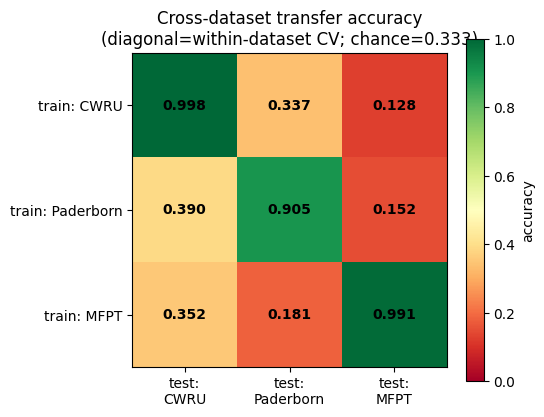

In [14]:
import matplotlib.pyplot as plt, numpy as np
fig, ax = plt.subplots(figsize=(5.5,4.5))
im = ax.imshow(mat, cmap='RdYlGn', vmin=0, vmax=1)
names = ['CWRU','Paderborn','MFPT']
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels([f'test:\n{n}' for n in names])
ax.set_yticklabels([f'train: {n}' for n in names])
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{mat[i,j]:.3f}', ha='center', va='center',
                color='black', fontweight='bold')
ax.set_title('Cross-dataset transfer accuracy\n(diagonal=within-dataset CV; chance=0.333)')
plt.colorbar(im, label='accuracy'); plt.tight_layout()
plt.savefig('/kaggle/working/transfer_matrix.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/transfer_matrix.pdf', bbox_inches='tight')
plt.show()

In [15]:
import numpy as np, pandas as pd
from scipy.stats import wasserstein_distance, pearsonr
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
import shap

le = LabelEncoder().fit(['IR','Normal','OR'])

def zt(a): return (a - a.mean(0))/(a.std(0)+1e-8)

def shap_importance(dfset):
    X = dfset[COLS].values; y = le.transform(dfset['fault'])
    m = XGBClassifier(random_state=42, eval_metric='mlogloss').fit(X, y)
    sv = np.abs(np.array(shap.TreeExplainer(m).shap_values(X)))
    fax = [ax for ax,s in enumerate(sv.shape) if s==len(COLS)][-1]
    other = tuple(ax for ax in range(sv.ndim) if ax!=fax)
    imp = sv.mean(axis=other).ravel()
    return imp/imp.sum()

imp_cwru = shap_importance(cwru)

pairs = {'CWRU-Paderborn':(cwru,pb), 'CWRU-MFPT':(cwru,mfpt), 'Paderborn-MFPT':(pb,mfpt)}
print("Per-pair domain gap + SHAP-divergence correlation:\n")
for name,(A,B) in pairs.items():
    Az, Bz = zt(A[COLS].values), zt(B[COLS].values)
    div = np.array([wasserstein_distance(Az[:,i], Bz[:,i]) for i in range(len(COLS))])
    gap = div.mean()                                  # single gap metric
    r,p = pearsonr(imp_cwru, div)                     # importance vs divergence
    print(f"{name:16s} | mean divergence (gap)={gap:.3f} | SHAP-div corr r={r:+.3f} (p={p:.2f})")

Per-pair domain gap + SHAP-divergence correlation:

CWRU-Paderborn   | mean divergence (gap)=0.285 | SHAP-div corr r=-0.124 (p=0.75)
CWRU-MFPT        | mean divergence (gap)=0.355 | SHAP-div corr r=-0.186 (p=0.63)
Paderborn-MFPT   | mean divergence (gap)=0.460 | SHAP-div corr r=+0.077 (p=0.84)


In [16]:
import shutil, os
dst='/kaggle/working/figures'; os.makedirs(dst, exist_ok=True)
for f in os.listdir('/kaggle/working'):
    if f.endswith(('.png','.pdf')):
        shutil.copy(f'/kaggle/working/{f}', f'{dst}/{f}')
shutil.make_archive('/kaggle/working/all_figures','zip',dst)
print("download all_figures.zip")

download all_figures.zip
